# IND320 project work, part 3

Viktor, NMBU, autumn 2026.

- GitHub repository: https://github.com/viktorbgulbrandsen/ind320-viktorbgulbrandsen
- Streamlit app: https://ind320-viktorbgulbrandsen.streamlit.app/
- Video link : https://drive.google.com/file/d/1ixxea-KfVpr1puz0Q0qfUHJNg7youUxf/view?usp=sharing

# API

Earlier, the reservoir data was given in relation to ten areas. We will now have a look at its relation to weather. The weather comes from the open-meteo API, which gives hourly historical weather for any point on the map from the ERA5 reanalysis. The first step we take is a plain call for one location:

In [55]:
import requests
import pandas as pd
import plotly.express as px
import plotly.io as pio

#plots as png so they show in the pdf export
pio.renderers.default = "png"

In [56]:
api_url = "https://archive-api.open-meteo.com/v1/archive"

#one location just south of trondheim and one week
#just to test the hit
params = {
    "latitude": 63.35166,
    "longitude": 10.39196,
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",
    "models": "era5",
    "hourly": "precipitation,temperature_2m",
}

response = requests.get(api_url, params=params)
print(response.status_code)
print(response.json())

429
{'reason': 'Daily API request limit exceeded. Please try again tomorrow.', 'error': True}


It is common that APIs have rate limits, so I load it from my local downloaded files instead. I keep one file per location, named by its latitude and longitude. Let us look at what we stored from the downloads, in a .parquet file:

In [57]:
#the same location from disk
#all of 2024
file = "data/weather_2024-01-01_2024-12-31/63.35166_10.39196.parquet"

df = pd.read_parquet(file)
print(df.shape)
df.head()

(8784, 11)


,time,precipitation,temperature_2m,rain,snowfall,relative_humidity_2m,wind_speed_10m,cloud_cover,pressure_msl,shortwave_radiation,et0_fao_evapotranspiration
0,2024-01-01 00:00:00,0.0,-3.8,0.0,0.0,66.0,7.06,96.0,1011.000000,0.0,0.03
1,2024-01-01 01:00:00,0.0,-3.8,0.0,0.0,66.0,7.08,97.0,1010.700012,0.0,0.03
2,2024-01-01 02:00:00,0.0,-3.6,0.0,0.0,66.0,7.00,99.0,1011.000000,0.0,0.03
3,2024-01-01 03:00:00,0.0,-3.4,0.0,0.0,65.0,7.00,98.0,1011.299988,0.0,0.03
4,2024-01-01 04:00:00,0.0,-3.3,0.0,0.0,65.0,6.92,98.0,1011.099976,0.0,0.03


And we print a simple plot of the temperature:

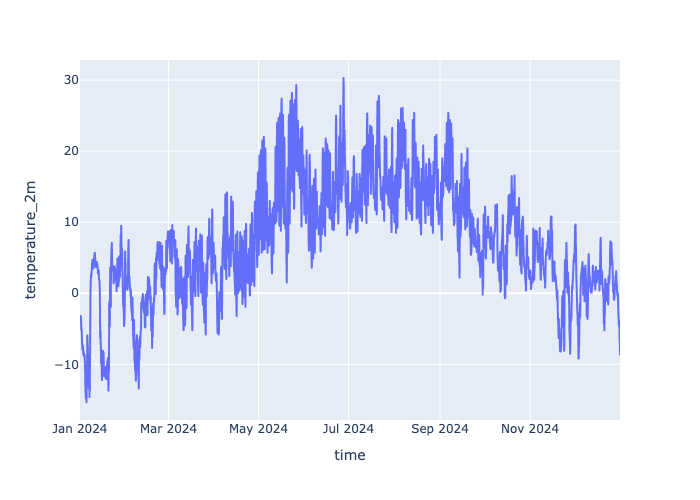

In [58]:
#one year of temperature for this one location
fig = px.line(df, x="time", y="temperature_2m")
fig.show()

This looks as it should, with low in January and warm in June. This is just one location though.

# Regions

Let us now consider how we get this data indexed by area in order to relate it to the reservoir data. Because the data we pulled from open-meteo is given for a single location, a latitude and a longitude, we can use the shapes of the areas from the map server behind atlas.nve.no to relate it by which area a location lies in.

In [59]:
import geopandas as gpd

#the price areas are layer 0 of nettomraader on nve's map server
#ask for every shape and the field with its name
url = "https://kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0/query"
params = {"where": "1=1", "outFields": "budomr", "returnGeometry": "true", "outSR": 25833, "f": "geojson"}

response = requests.get(url, params=params)
response.raise_for_status()
price_areas = gpd.read_file(response.text)
price_areas

,budomr,geometry
0,NO 1,"POLYGON ((337473.63 6970542.97, 337414.99 6970..."
1,NO 2,"POLYGON ((-9833.91 6726499.86, -9861.7 6726719..."
2,NO 3,"POLYGON ((308588.7 7261519.43, 295281.7 726804..."
3,NO 4,"POLYGON ((973920.93 7962739.19, 973255.49 7962..."
4,NO 5,"POLYGON ((101466.43 6881318.54, 101382.41 6881..."


The schema returns five rows, one per price area, with the name of the area in `budomr` and its shape in `geometry`. Let us plot them:

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

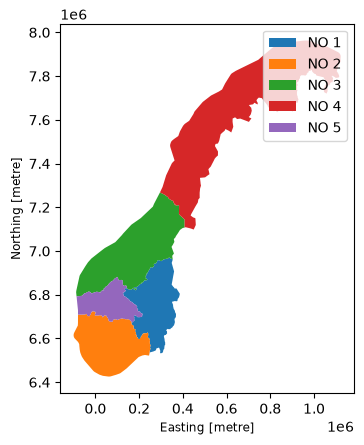

In [60]:
#five shapes and one per price area
price_areas.plot(column="budomr", legend=True)

That is the five price areas. The reservoir data also comes for the four VASS areas, which are not on this map. They are made from NVE's own regions, which is another layer on the same server. I move the request into a function, `read_layer` in `utils/regions.py`, which also keeps the layer as a file so NVE is only asked once:

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

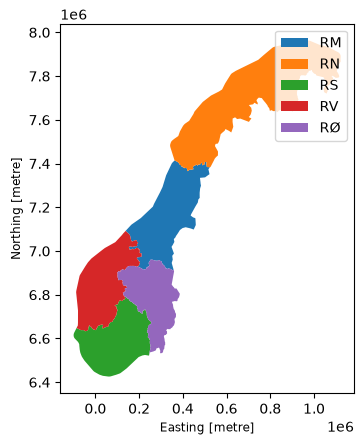

In [61]:
#the request is moved into read_layer in utils/regions.py
#it keeps each layer as a shapefile so nve is only asked once
#the second layer is nve's own five regions which the vass areas are made of
from utils.regions import read_layer

nve_regions = read_layer("nve_region")
nve_regions.plot(column="REGION", legend=True)

There are five regions but they are not the correct five. We map the data from the reservoir VASS areas and the five regions from NVE. The east is RØ and RS, the north is RM and RN. I keep this as a table, `AREAS` in `utils/regions.py`:

In [62]:
#which shapes each of the ten areas of magasinstatistikk is made of
#the price areas come one to one
#for the vass areas east is rø and rs together and north is split into rm and rn
from utils.regions import AREAS

AREAS

{'NO': ('budomraade', ['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']),
 'NO1': ('budomraade', ['NO 1']),
 'NO2': ('budomraade', ['NO 2']),
 'NO3': ('budomraade', ['NO 3']),
 'NO4': ('budomraade', ['NO 4']),
 'NO5': ('budomraade', ['NO 5']),
 'VASS1': ('nve_region', ['RØ', 'RS']),
 'VASS2': ('nve_region', ['RV']),
 'VASS3': ('nve_region', ['RM']),
 'VASS4': ('nve_region', ['RN'])}

I take NO3, which we download weather for:

104220 km2


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

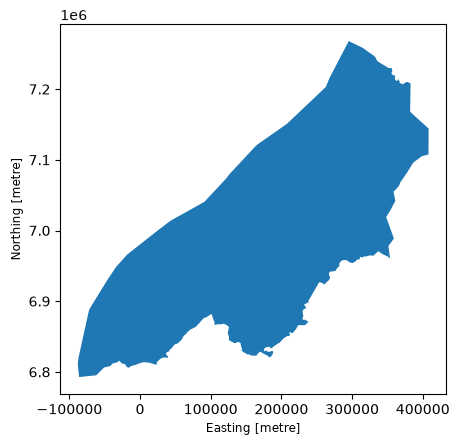

In [63]:
#no3 straight from the layer
#the coordinates are in metres so the area comes out in m2
no3 = price_areas[price_areas["budomr"] == "NO 3"]
print(round(no3.area.sum() / 1e6), "km2")
no3.plot()

104 220 km2 is too much since the shape also covers the sea, so we cut it:

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

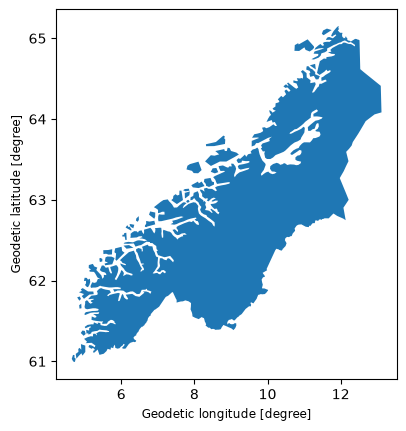

In [64]:
#104 000 km2 is far too much for no3
#the shape has no coastline so it covers the sea outside as well
#random points in it would land in the water
#region_shape cuts the area with nve's land cover and gives it in lon and lat
from utils.regions import region_shape

shape = region_shape("NO3")
gpd.GeoSeries([shape], crs=4326).plot()

Now it looks like NO3. Let us draw 1000 random locations inside it. The seed is fixed, so the same locations come out every time:

In [65]:
#1000 random points inside no3
#the seed is fixed so the same points come out every time
#the first point is the location from the api section
from utils.regions import draw_points

points = draw_points("NO3", 1000, 320)
print(points.shape)
points.head()

(1000, 2)


,lon,lat
0,10.391964,63.351658
1,9.887177,62.855288
2,9.551506,63.054151
3,11.091896,64.609911
4,11.681513,64.336747


The first one is the location south of Trondheim from the API section. Let us plot them on top of the area:

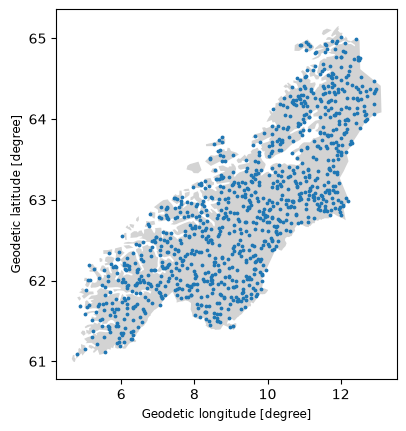

In [66]:
#the points on top of the area
ax = gpd.GeoSeries([shape], crs=4326).plot(color="lightgrey")
ax.scatter(points["lon"], points["lat"], s=3)

The locations cover the whole area. The same is done for all ten areas. The locations are kept as files, since the weather files are named after them:

In [67]:
#sample_points keeps the 1000 points of an area as a file
#the weather files are named after the points so they must stay the same
from utils.regions import sample_points

for area in AREAS:
    print(area, len(sample_points(area)))

NO 1000
NO1 1000
NO2 1000
NO3 1000
NO4 1000
NO5 1000
VASS1 1000
VASS2 1000
VASS3 1000
VASS4 1000


# Weather for NO3

With the locations in place we can download for a whole area. The function `fetch_weather` in `utils/weather.py` takes an area and a time interval. It looks up the 1000 locations of the area, downloads the ones that are not on disk yet and reads everything back from the files:

In [68]:
#the function from the task takes an area and a time interval
#no3 for 2024 is on disk from the earlier run so no request is made now
from utils.weather import fetch_weather

weather = fetch_weather("NO3", "2024-01-01", "2024-12-31")
print(weather.shape)
weather.head()

(8784000, 13)


,lon,lat,time,precipitation,temperature_2m,rain,snowfall,relative_humidity_2m,wind_speed_10m,cloud_cover,pressure_msl,shortwave_radiation,et0_fao_evapotranspiration
0,10.391964,63.351658,2024-01-01 00:00:00,0.0,-3.8,0.0,0.0,66.0,7.06,96.0,1011.000000,0.0,0.03
1,10.391964,63.351658,2024-01-01 01:00:00,0.0,-3.8,0.0,0.0,66.0,7.08,97.0,1010.700012,0.0,0.03
2,10.391964,63.351658,2024-01-01 02:00:00,0.0,-3.6,0.0,0.0,66.0,7.00,99.0,1011.000000,0.0,0.03
3,10.391964,63.351658,2024-01-01 03:00:00,0.0,-3.4,0.0,0.0,65.0,7.00,98.0,1011.299988,0.0,0.03
4,10.391964,63.351658,2024-01-01 04:00:00,0.0,-3.3,0.0,0.0,65.0,6.92,98.0,1011.099976,0.0,0.03


That is 8.8 million rows, one row per location and hour. To get one series for the whole area we take the mean over the 1000 locations for every hour:

In [69]:
#8.8 million rows is one row per point and hour
#the mean over the 1000 points gives one row per hour for the whole area
from utils.weather import region_mean

means = region_mean(weather)
print(means.shape)
means.head()

(8784, 11)


,time,precipitation,temperature_2m,rain,snowfall,relative_humidity_2m,wind_speed_10m,cloud_cover,pressure_msl,shortwave_radiation,et0_fao_evapotranspiration
0,2024-01-01 00:00:00,0.0056,-6.1124,0.0003,0.00371,71.456001,5.10527,90.791000,1010.317505,0.0,0.01816
1,2024-01-01 01:00:00,0.0053,-6.2634,0.0000,0.00371,71.491997,5.17335,91.063004,1010.095703,0.0,0.01816
2,2024-01-01 02:00:00,0.0053,-6.2150,0.0000,0.00371,71.032997,5.24842,92.072998,1010.103699,0.0,0.01879
3,2024-01-01 03:00:00,0.0053,-6.2368,0.0000,0.00371,70.542000,5.24455,90.251999,1010.232300,0.0,0.01924
4,2024-01-01 04:00:00,0.0048,-6.1574,0.0000,0.00336,70.230003,5.28462,90.911003,1010.021606,0.0,0.01970


One row per hour for NO3. This is the data we look at in the next two sections.

# Outliers

Let us first look at the precipitation. We plot the mean for NO3 hour by hour:

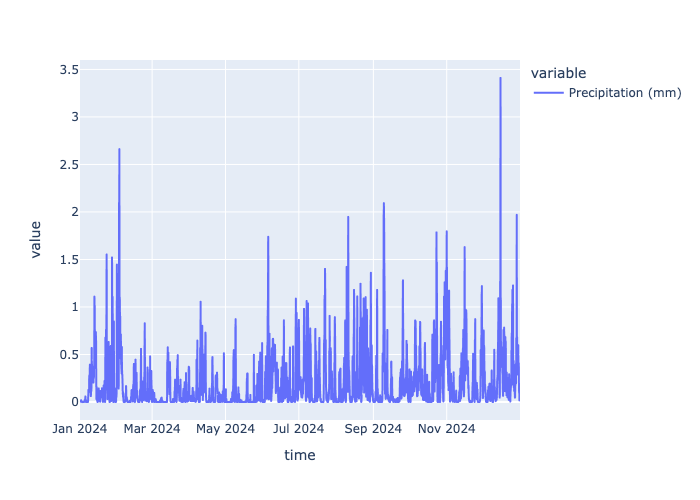

In [70]:
#time as index so the plots get dates on the axis
hourly = means.set_index("time")
rain = hourly["precipitation"].rename("Precipitation (mm)")

fig = px.line(rain)
fig.show()

To find the hours that stand out, we first take away the slow changes over the year. The Discrete Cosine Transform splits the series into cosine waves. We set the slowest waves to zero and transform back:

In [71]:
import numpy as np
from scipy.fft import dct, idct

#coefficient k holds k/2 cosine cycles over the year
#so the first 25 are everything up to 12 cycles a year
#set them to zero and transform back
coefficients = dct(rain.to_numpy(), type=1, norm="forward")
coefficients[:25] = 0
satv = idct(coefficients, type=1, norm="forward")

What is left is how much each hour differs from the season it is in, which the task calls the SATV. The limits are put three standard deviations from the middle. We use the median and the MAD (the median absolute deviation) for this, so the outliers themselves do not move the limits:

In [72]:
from scipy.stats import median_abs_deviation

#median and mad so the outliers themselves do not move the limits
centre = np.median(satv)
spread = median_abs_deviation(satv, scale="normal")
low = centre - 3 * spread
high = centre + 3 * spread
outside = (satv < low) | (satv > high)
print(round(low, 3), round(high, 3), outside.sum())

-0.54 0.405 635


635 of the 8784 hours are outside the limits. The same steps are put in a function, `spc_outliers` in `utils/quality.py`. It takes the cut-off and the number of standard deviations as parameters, and returns the plot and a summary:

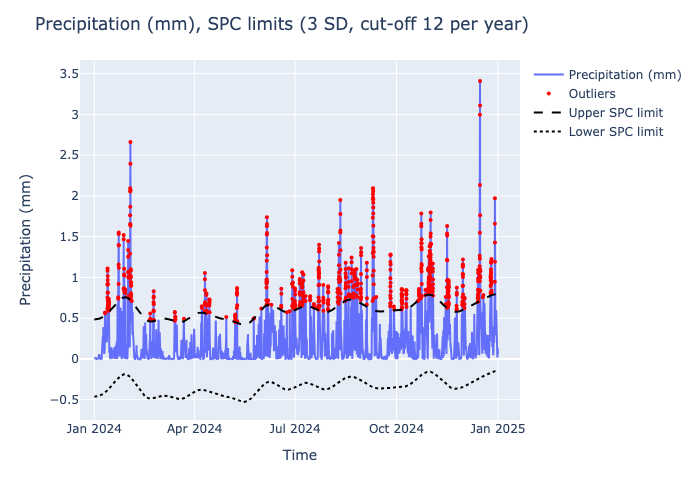

635 0.072


,time,value
0,2024-01-10 17:00:00,0.5694
1,2024-01-10 18:00:00,0.5607
2,2024-01-12 21:00:00,0.6185
3,2024-01-12 22:00:00,0.7541
4,2024-01-12 23:00:00,0.9132


In [73]:
from utils.quality import spc_outliers

fig, summary = spc_outliers(rain)
fig.show()
print(summary["n_outliers"], round(summary["share"], 3))
summary["outliers"].head()

The function finds the same 635 hours. The limits in the plot follow the slow part that the filter took away, and the filtered series itself is not plotted. Let us test the function with a stricter limit and with a higher cut-off:

372
654


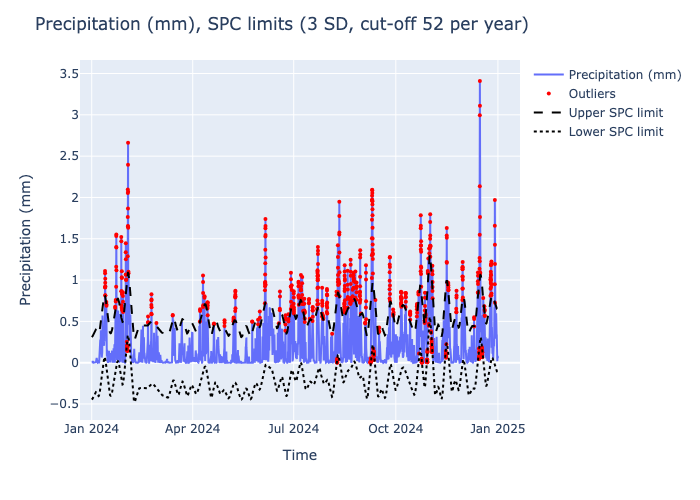

In [74]:
#test with a stricter limit and with a higher cut-off
fig, summary = spc_outliers(rain, cutoff=12, n_std=4)
print(summary["n_outliers"])
fig, summary = spc_outliers(rain, cutoff=52, n_std=3)
print(summary["n_outliers"])
fig.show()

With the default settings, 7 percent of the hours are outliers, which is a lot for three standard deviations. Precipitation is zero or close to it most of the time, so the spread comes out small and every shower ends up outside. All of them are above the upper limit.

# Anomalies

Now the temperature. We plot the mean for NO3 hour by hour:

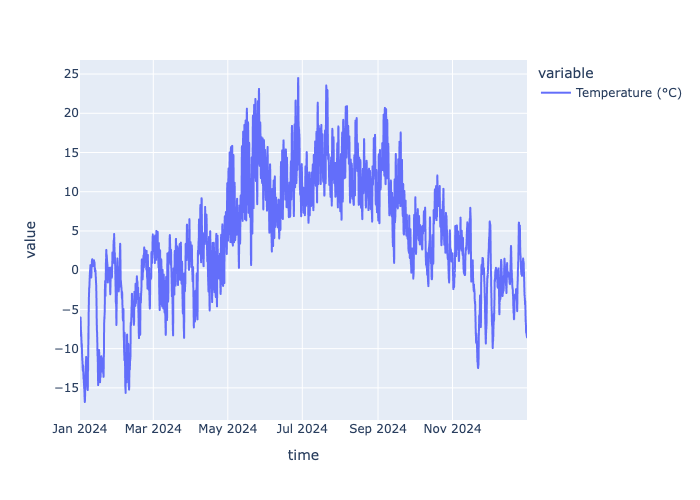

In [75]:
temp = hourly["temperature_2m"].rename("Temperature (°C)")

fig = px.line(temp)
fig.show()

For the temperature we use another method, the Local Outlier Factor (LOF). It compares each hour with its nearest neighbours, and marks the hours that lie more alone than their neighbours do. We give it two things per hour, the temperature and the time, so an hour is compared with the hours around it:

In [76]:
from sklearn.neighbors import LocalOutlierFactor

#the temperature in standard deviations and the time as a second feature
#one hour counts as 0.01 so a day is about a quarter of a standard deviation
z = (temp - temp.mean()) / temp.std()
hours = np.arange(len(temp))
features = np.column_stack([z, 0.01 * hours])

#20 neighbours as in the book
#contamination is the share that gets marked
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01)
marked = lof.fit_predict(features) == -1
print(marked.sum())

88


88 hours are marked, which is the 1 percent we asked for. The same steps are in the function `lof_anomalies` in `utils/quality.py`, with the share as a parameter:

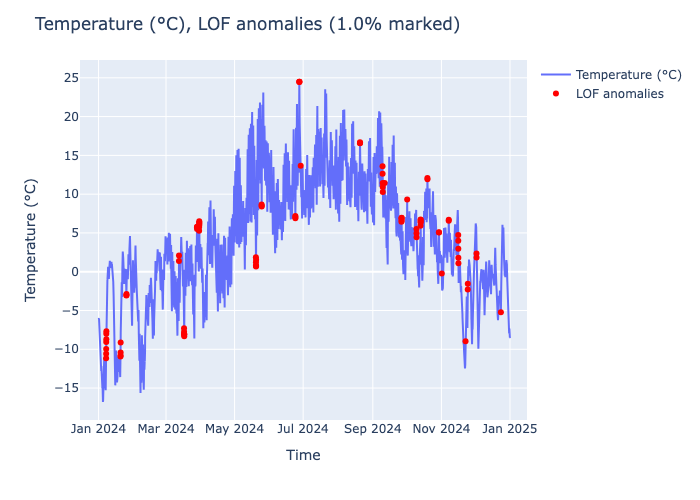

88 0.01


,time,value,lof
0,2024-01-07 17:00:00,-11.166599,1.540982
1,2024-01-07 18:00:00,-10.570100,1.637019
2,2024-01-07 19:00:00,-9.977500,1.740339
3,2024-01-07 20:00:00,-9.065901,1.710575
4,2024-01-07 21:00:00,-8.005800,1.638650


In [77]:
from utils.quality import lof_anomalies

fig, summary = lof_anomalies(temp)
fig.show()
print(summary["n_anomalies"], round(summary["share"], 3))
summary["anomalies"].head()

Let us test the function with a smaller and a larger share:

44
440


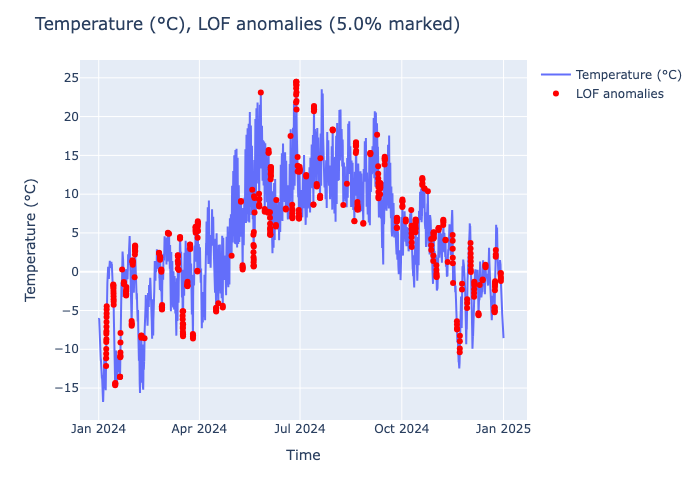

In [78]:
#test with half a percent and with five percent
fig, summary = lof_anomalies(temp, contamination=0.005)
print(summary["n_anomalies"])
fig, summary = lof_anomalies(temp, contamination=0.05)
print(summary["n_anomalies"])
fig.show()

The count follows the share, since LOF marks as many as we ask for. With the default, the 88 hours lie on 30 different days spread over the year. The coldest hour of the year is not among them. LOF marks hours that differ from the hours around them, not the extremes of the year.

# STL

Now back to the reservoirs. The fill level comes from the NVE API, with the function from part 2. We take NO3, which gives one value per week since 1995:

1661 1995-01-08 2026-11-01


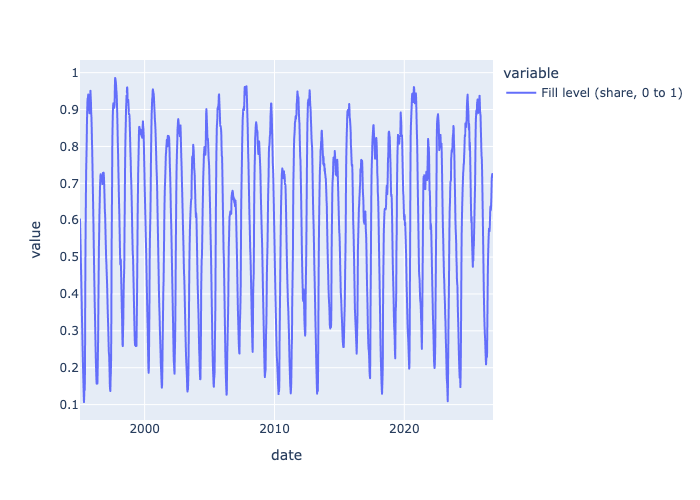

In [79]:
from utils.nve import fetch_reservoirs

#the same area as the weather
#one weekly series with the date as index
reservoirs = fetch_reservoirs()
no3 = reservoirs[(reservoirs["area_type"] == "EL") & (reservoirs["area_no"] == 3)]
fill = no3.set_index("date")["fill_level"].rename("Fill level (share, 0 to 1)")
print(len(fill), fill.index[0].date(), fill.index[-1].date())

fig = px.line(fill)
fig.show()

STL splits a series into a trend, a season that repeats, and what is left. Let us first try it straight from statsmodels. One season is one year, which is 52 weeks:

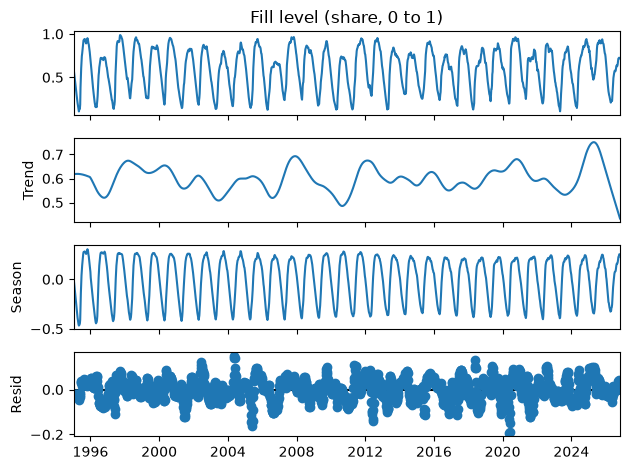

In [80]:
from statsmodels.tsa.seasonal import STL

#one season is one year which is 52 weeks
fit = STL(fill, period=52).fit()
fig = fit.plot()

The four panels are the fill level, the trend, the season and the remainder. I put this in a function, `stl_plot` in `utils/quality.py`. It draws the same four panels with plotly, and takes the seasonal smoother, the trend smoother and robust as parameters:

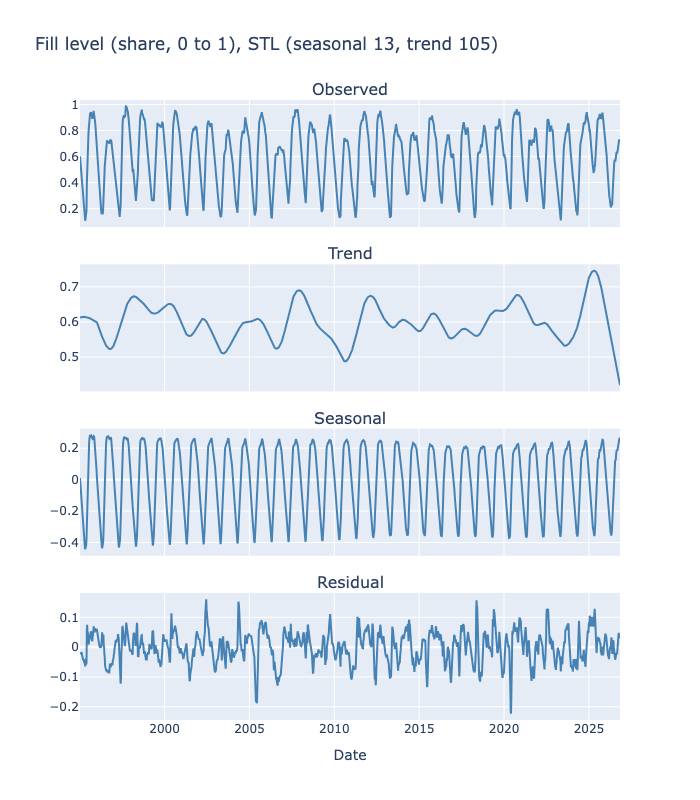

In [81]:
from utils.quality import stl_plot

fig = stl_plot(fill)
fig.show()

Let us test it with other smoothers and with robust on:

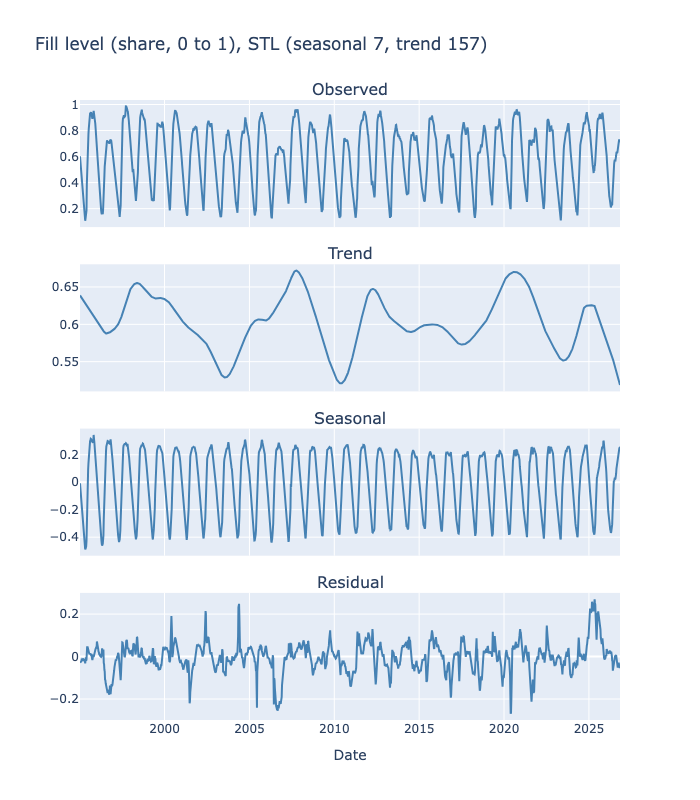

In [82]:
#a shorter seasonal smoother lets the season change faster from year to year
#a longer trend smoother gives a calmer trend
#robust gives the odd weeks less weight
fig = stl_plot(fill, seasonal=7, trend=157, robust=True)
fig.show()

The season is the largest part. The fill level is lowest in late April and highest in mid October. The trend falls steeply at the very end. The last part of a trend only has data on one side, so we should not read much into that. The largest remainder is in the spring of 2020.

# Spectrogram

The same fill level can also be looked at as frequencies. A spectrogram takes one window of the series at a time and shows which frequencies are in it, so we see how they change over the years. The function `spectrogram_plot` in `utils/quality.py` takes the length of the window and the overlap between the windows as parameters. The default window is 104 weeks, which is two years:

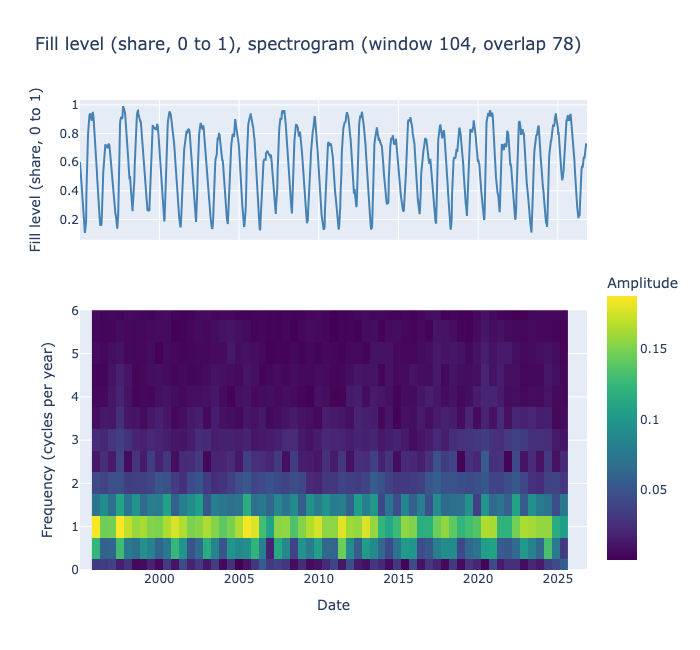

In [83]:
from utils.quality import spectrogram_plot

fig = spectrogram_plot(fill)
fig.show()

There is one clear band, at one cycle per year, and it is there in all the years. Let us test the function with a window of one year:

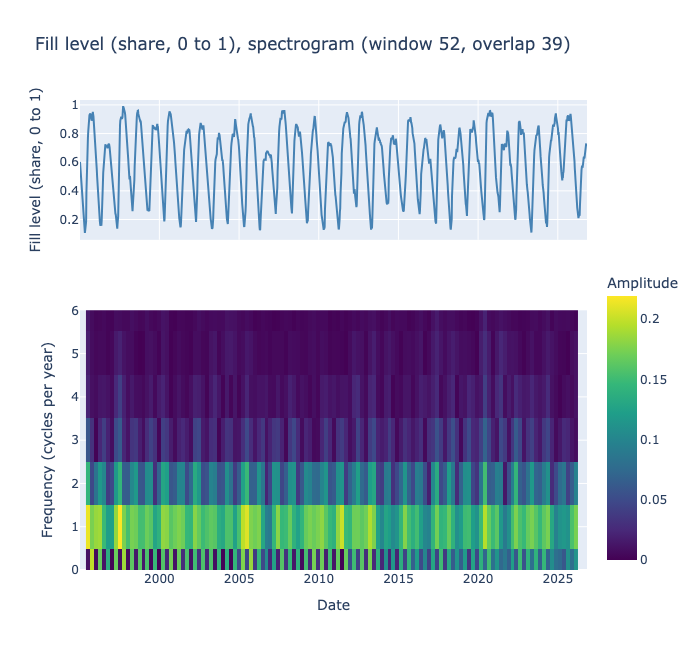

In [84]:
#a shorter window follows the changes in time better
#but it tells the frequencies less apart
fig = spectrogram_plot(fill, window_length=52, overlap=39)
fig.show()

With the shorter window the band gets wider, since a window of one year can only tell whole cycles per year apart. In return it follows the changes from year to year more closely.

# App

The app got two new pages. Fill level decomposition has the STL in one tab and the spectrogram in the other. Weather outliers has the SPC outliers in one tab and the LOF anomalies in the other. Both pages use the functions from `utils/quality.py` that we tested above. The weather page reads the weather of the chosen area from MongoDB, and downloads it from open-meteo if the area is not there yet.

In [85]:
#print the app code here as well like in part 2
#the menu at the root then the two new pages and the code they share
!cat ../streamlit_app.py views/*.py utils/*.py

import sys
from pathlib import Path

import streamlit as st

#streamlit.app runs this file so it has to stay at the root
#part 2 and part 3 both live in the app
PART2 = Path(__file__).parent / "project2"
PART3 = Path(__file__).parent / "project3"

#project3 goes first
#its utils package also reaches the files of project2/utils
#so utils.nve and utils.mongo and utils.quality all import
sys.path.insert(0, str(PART2))
sys.path.insert(0, str(PART3))

#wide layout for every page
#set once before the navigation
st.set_page_config(layout="wide")

#one flat menu
#the reservoir pages come first then weather then the power flows
pages = [
    st.Page(str(PART2 / "views/1_home.py"), title="Home"),
    st.Page(str(PART2 / "views/5_latest_week.py"), title="Latest week"),
    st.Page(str(PART2 / "views/2_table.py"), title="Data table"),
    st.Page(str(PART2 / "views/3_plot.py"), title="Plot"),
    st.Page(str(PART3 / "views/6_decomposition.py"), title="Fill level decomposition"),
    st.Page(str(PA

# Log

**29 october**

The weather is to be fetched for the same ten areas as the reservoir data, so I started with the areas. atlas.nve.no is a viewer on top of NVE's map server, so I ask the server for the layers directly and keep them as shapefiles. The price areas are one layer. The VASS areas are made from NVE's regions, with RØ and RS together as the east and RM and RN as the two in the north. The shapes reach far out in the sea, NO3 was 104 000 km2, so I cut them with NVE's land cover before drawing 1000 random locations in each. The locations are drawn in an equal area projection with a fixed seed, so they are spread evenly and are the same every time.

**3 november**

open-meteo counts a request by how much it asks for. One location for a year is about 26 calls, so NO3 with 1000 locations is about 26 000 calls against 10 000 free per day. The download function therefore keeps one file per location and only asks for the locations that are missing. That way it could be started again and go on where it stopped, until all of NO3 for 2024 was on disk. The notebook reads from these files and shows the limit in its first call.

**5 and 6 november**

The four analyses are in `utils/quality.py`. For the outliers the precipitation is high-pass filtered with the DCT, and the limits come from the median and the MAD. With the defaults 7 percent of the hours are outside, since precipitation is zero most of the time. For LOF I use the time as a second feature, so an hour is compared with the hours around it. STL and the spectrogram are done on the weekly fill level, with the frequencies in cycles per year.

**8 november, the app**

The app got two new pages with two tabs each, one page for STL and the spectrogram and one for the outliers and the anomalies. The area is picked with the same radio as on the data table page and pills for the area. The choice is kept in the session state, so it follows from one page to the other. The server at streamlit.app has no files of mine, so the weather page reads from MongoDB and downloads from open-meteo only when an area is missing. It uses 50 locations per area, since their mean precipitation correlates 0.99 with the mean of all 1000. I did not make a separate download page, a spinner is enough.

**10 november**

The TA asked for an "All columns" choice on the plot page and for the CSV to be taken out of the repository, and both are done. The menu is one list with the reservoir pages first, then the weather and the power flows. Before the merge I ran the app locally from only the files that are in git, to see that every page loads.

# AI Log

**29 october**

For the areas I asked Claude: "atlas.nve.no only shows the areas in a map viewer, how do i get the shapes into python". It answered: "The viewer reads its layers from NVE's own map server, and you can ask that server directly. Every layer has a query endpoint that can return GeoJSON:

```python
url = "https://kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0/query"
params = {"where": "1=1", "outFields": "budomr", "f": "geojson"}
price_areas = gpd.read_file(requests.get(url, params=params).text)
```

The price areas are layer 0 of Nettomraader, and NVE's regions are in Administrasjon2."

NO3 came out as 104 000 km2, which is too much. I asked why, and the answer was that the shapes have no coastline and run straight out over the sea. Claude suggested cutting them with the land cover layer on the same server, where everything except "Havflate" is land.

I asked: "how do i draw random points evenly inside a shape". It answered: "A simple and robust way is rejection sampling:

1. Draw uniform points in the bounding box of the shape.
2. Keep the ones that fall inside.
3. Repeat until you have enough.

One thing to watch: do the drawing in an equal area projection such as EPSG:3035. In plain longitude and latitude the points come out denser in the north, because a degree of longitude gets shorter there."

**3 november**

I asked: "can i ask open-meteo for many locations in one request". It answered: "Yes. Give the latitudes and the longitudes as comma separated lists, and the answer is a list with one entry per location, in the same order. Note that open-meteo counts a request by its size and not as one call: the number of locations times days/14 times variables/10. One location for all of 2024 with ten variables is about 26 calls, so 1000 locations is about 26 000."

That is more than the free limit for a day, so I asked how to not lose what was already downloaded. Claude suggested one file per location, and to only ask for the locations without a file. The first version of the function had a lot of pacing and retries around this. I had Claude take that out again, so it reads like the code in parts 1 and 2.

**5 november**

For the outliers I asked what to use for the limits when the outliers themselves pull the standard deviation up. Claude pointed to the median and the MAD: "`median_abs_deviation(satv, scale="normal")` gives the MAD scaled so that it equals the standard deviation for normal data, so three standard deviations still means what you expect."

Claude caught that the inverse cosine transform has to be of the same type as the forward one, type 1 with `norm="forward"` both ways. Otherwise the filtered series does not come back on the right scale.

For LOF I asked what to give it besides the temperature. The answer was to use the time as a second feature, as in the book, so an hour is compared with the hours around it and not with the same temperature at another time of the year.

**8 november**

For the app I used Claude for a few specific things.

I asked: "how do i keep the chosen area when i go from one page to the other". It answered: "Streamlit drops the state of a widget when you leave its page, so the choice has to be stored yourself. `st.session_state` lives for the whole session:

```python
st.session_state.setdefault("region", "NO3")
region = st.pills("Area", options, default=st.session_state["region"])
st.session_state["region"] = region
```

Both pages read and write the same key, so the area follows the user."

I asked: "the server at streamlit.app does not have my downloaded files, where does the weather page get its data". It answered: "Use the MongoDB you already have from part 2. Look for a document for the area first, and only call open-meteo when it is missing, then store the result. A new area costs one request the first time and nothing after that."

I also asked how many locations the app needs. Claude measured that the mean of 50 locations correlates 0.99 with the mean of all 1000 for the precipitation, so the app uses 50.

**10 november**

I had Claude check the download before I wrote the notebook. All 1000 files are there with all 8784 hours, and locations next to each other have the very same precipitation series far more often than two random locations, so every location got its own weather.